# 04 · Deep Learning: rede densa
[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jessicapmartins/previsao-faltas-consultas/blob/main/notebooks/04_deep_learning.ipynb)

**Pergunta:** uma rede neural supera o Gradient Boosting nesta base tabular? Em tabelas com poucas variáveis o boosting costuma ganhar; o objetivo é **testar e mostrar o raciocínio**.

*Não precisa de GPU: a rede é pequena e treina em poucos minutos na CPU do Colab.*

In [ ]:
# Funções de apoio do projeto (mesma carga, mesmas variáveis e mesmo modelo em todos os notebooks)
import os, sys, urllib.request
try:
    import google.colab
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jessicapmartins/previsao-faltas-consultas/main/src/apoio.py', '/content/apoio.py')
    sys.path.insert(0, '/content')
except ModuleNotFoundError:
    sys.path.insert(0, '../src')
import apoio, pandas as pd, numpy as np

con, DADOS, CSV = apoio.conectar()

def q(sql):
    """Roda uma consulta SQL no banco de consultas e devolve um DataFrame."""
    return pd.read_sql(sql, con)

apoio.garantir(con, CSV, 'previsoes')
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
import keras
from keras import layers
keras.utils.set_random_seed(42)

Mounted at /content/drive
Tabelas de origem não encontradas: recriando a partir do CSV...
base_modelo não encontrada: recriando com o SQL do notebook 02...
previsoes não encontrada: retreinando o modelo final do notebook 03...


## 1. Mesmas variáveis e mesma separação do notebook 03, padronizadas
Redes neurais precisam de variáveis na mesma escala. O padronizador aprende média e desvio **só no treino**. Os últimos dias do treino viram a validação, usada para parar o treino na hora certa.

In [ ]:
base = q('SELECT * FROM base_modelo')
treino, teste = apoio.separar(base)
taxa_bairro, taxa_geral = apoio.taxas_bairro(treino)

corte_val = '2016-05-20'                                   # últimos dias do treino = validação
tr, val = treino[treino.data_consulta < corte_val], treino[treino.data_consulta >= corte_val]

escala = StandardScaler().fit(apoio.preparar_X(tr, taxa_bairro, taxa_geral))
prep = lambda d: escala.transform(apoio.preparar_X(d, taxa_bairro, taxa_geral)).astype('float32')
X_tr, X_val, X_te = prep(tr), prep(val), prep(teste)
y_tr, y_val, y_te = tr.faltou.values, val.faltou.values, teste.faltou.values
print(X_tr.shape, X_val.shape, X_te.shape)

(63528, 14) (11746, 14) (35240, 14)


## 2. A rede
Dense(32) → Dropout(30%) → Dense(16) → Dense(1, sigmoide). A saída é a probabilidade de falta. **Early stopping:** para quando a perda na validação piora por 5 épocas seguidas e volta aos melhores pesos.

In [ ]:
rede = keras.Sequential([
    keras.Input(shape=(X_tr.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),                     # desliga 30% dos neurônios a cada passo: reduz decoreba
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])
rede.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
             metrics=[keras.metrics.AUC(name='auc'), keras.metrics.AUC(curve='PR', name='pr_auc')])
rede.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

Épocas treinadas: 48


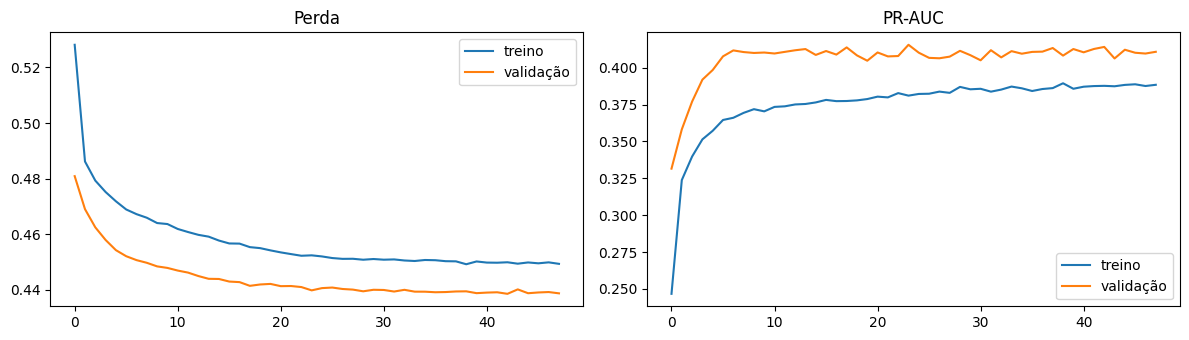

In [ ]:
parar = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
hist = rede.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=60, batch_size=256,
                callbacks=[parar], verbose=0)
print('Épocas treinadas:', len(hist.history['loss']))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(hist.history['loss'], label='treino'); ax[0].plot(hist.history['val_loss'], label='validação')
ax[0].set_title('Perda'); ax[0].legend()
ax[1].plot(hist.history['pr_auc'], label='treino'); ax[1].plot(hist.history['val_pr_auc'], label='validação')
ax[1].set_title('PR-AUC'); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Comparar com o Gradient Boosting nas mesmas métricas e no mesmo teste

In [ ]:
p_rede = rede.predict(X_te, verbose=0).ravel()
gb = teste[['consulta_id']].merge(q('SELECT consulta_id, risco FROM previsoes'), on='consulta_id')['risco'].values  # mesmo teste, mesma ordem

def metricas(y, p):
    topo = np.argsort(-p)[:int(0.2 * len(p))]
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'Brier': brier_score_loss(y, p), 'recall nos 20% de maior risco': y[topo].sum() / y.sum()}

comparacao = pd.DataFrame({'Rede densa (Keras)': metricas(y_te, p_rede),
                           'Gradient Boosting (notebook 03)': metricas(y_te, gb)}).T
comparacao.round(3)

,ROC-AUC,PR-AUC,Brier,recall nos 20% de maior risco
Rede densa (Keras),0.729,0.341,0.137,0.380
Gradient Boosting (notebook 03),0.734,0.342,0.138,0.377


## Conclusão
_Compare as duas linhas da tabela acima: a rede supera o Gradient Boosting? Vale a complexidade a mais (padronização, validação, épocas)?_

A rede densa empatou com o Gradient Boosting: ROC-AUC 0,729 contra 0,734, PR-AUC 0,341 contra 0,342 e recall nos 20% de maior risco de 38,0% contra 37,7%. As diferenças estão na terceira casa decimal, pequenas demais para apontar um vencedor com uma única semana de teste. O treino parou na época 48 pelo early stopping. A perda de validação ficou abaixo da de treino o tempo todo; um motivo provável é o dropout, que só atua durante o treino.

Vale a complexidade? Não. A rede exige padronização, conjunto de validação e escolha de camadas e épocas, é mais difícil de explicar e não ganhou nada. Nesta base tabular com 14 variáveis, o Gradient Boosting continua como modelo final. Uma rede faria mais sentido com outro tipo de dado, como texto de prontuário ou um histórico longo de consultas.

## Gravar no Google Drive
Fecha o banco e força o Drive a gravar agora. Sem isso, o próximo notebook pode não enxergar as tabelas novas.

In [ ]:
con.commit()
con.close()
try:
    from google.colab import drive
    drive.flush_and_unmount()
    print('Banco gravado no Google Drive.')
except ModuleNotFoundError:
    print('Fora do Colab: nada a sincronizar.')

Banco gravado no Google Drive.
